In [1]:

# Capstone Project: Customer Churn - Where do we lose customers, and what should we do about it?
# Step 1: Load the raw data, check its quality, clean it and add useful columns

import os
import numpy as np
import pandas as pd
from google.colab import files

os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# ---------- Load the raw data (upload customer_churn.csv) ----------
uploaded = files.upload()
raw_name = None
for name in uploaded:
    if 'churn' in name.lower() or 'customer' in name.lower():
        raw_name = name

if raw_name is None:
    print("Error: please upload the customer churn file (customer_churn.csv).")
else:
    raw = pd.read_csv(raw_name)
    raw.to_csv('data/raw_data.csv', index=False)          # an untouched copy of the original data
    print("Raw data loaded:", raw.shape[0], "rows and", raw.shape[1], "columns")
    print()
    print(raw.head())

    # ---------- Data quality report ----------
    print()
    print("=" * 60)
    print("DATA QUALITY REPORT")
    print("=" * 60)
    expected = ['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract',
                'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']
    missing_cols = [c for c in expected if c not in raw.columns]
    if missing_cols:
        print("Error: these columns are missing:", missing_cols)
    else:
        quality = []
        quality.append(("Rows (needs 500 or more)", len(raw), "OK" if len(raw) >= 500 else "TOO FEW"))
        quality.append(("Missing values", int(raw.isnull().sum().sum()), "OK" if raw.isnull().sum().sum() == 0 else "FIX"))
        quality.append(("Duplicate rows", int(raw.duplicated().sum()), "OK" if raw.duplicated().sum() == 0 else "FIX"))
        quality.append(("Duplicate customer IDs", int(raw['CustomerID'].duplicated().sum()),
                        "OK" if raw['CustomerID'].duplicated().sum() == 0 else "FIX"))
        quality.append(("Churn values other than 0 or 1", int((~raw['Churn'].isin([0, 1])).sum()),
                        "OK" if raw['Churn'].isin([0, 1]).all() else "FIX"))
        quality.append(("Tenure outside 0 to 72 months", int(((raw['Tenure'] < 0) | (raw['Tenure'] > 72)).sum()),
                        "OK" if raw['Tenure'].between(0, 72).all() else "CHECK"))
        quality.append(("Monthly charges at or below 0", int((raw['MonthlyCharges'] <= 0).sum()),
                        "OK" if (raw['MonthlyCharges'] > 0).all() else "FIX"))

        # Outliers with the IQR rule
        for col in ['MonthlyCharges', 'TotalCharges']:
            q1, q3 = raw[col].quantile([0.25, 0.75])
            iqr = q3 - q1
            n_out = int(((raw[col] < q1 - 1.5 * iqr) | (raw[col] > q3 + 1.5 * iqr)).sum())
            quality.append((f"Outliers in {col} (IQR rule)", n_out, "OK" if n_out == 0 else "CHECK"))

        # Do the numbers make sense together? TotalCharges should be close to Tenure x MonthlyCharges
        expected_total = raw['Tenure'] * raw['MonthlyCharges']
        close = ((raw['TotalCharges'] - expected_total).abs() / expected_total) <= 0.10
        corr = np.corrcoef(raw['TotalCharges'], expected_total)[0, 1]
        quality.append(("TotalCharges within 10% of Tenure x MonthlyCharges", f"{close.mean() * 100:.1f}% of rows",
                        "PROBLEM" if close.mean() < 0.9 else "OK"))
        print(pd.DataFrame(quality, columns=['Check', 'Result', 'Status']).to_string(index=False))
        print()
        print(f"Correlation between TotalCharges and Tenure x MonthlyCharges: {corr:.2f}")
        print("In real billing data this should be close to 1. Here it is close to 0, so TotalCharges")
        print("cannot be trusted. We keep it in the file, mark it, and do NOT use it in the analysis.")

        # ---------- Cleaning ----------
        clean = raw.copy()
        for col in ['CustomerID', 'Contract', 'PaymentMethod', 'PaperlessBilling']:
            clean[col] = clean[col].str.strip()                    # remove stray spaces
        clean = clean.drop_duplicates()

        # ---------- New columns (feature engineering) ----------
        clean['TenureGroup'] = pd.cut(clean['Tenure'], bins=[0, 11, 23, 47, 72],
                                      labels=['0-11 months', '12-23 months', '24-47 months', '48+ months'])
        clean['FirstYear'] = (clean['Tenure'] <= 11).astype(int)           # 1 = still in the first year
        clean['ChargeBand'] = pd.qcut(clean['MonthlyCharges'], 4,
                                      labels=['Low', 'Medium', 'High', 'Very high'])
        clean['ExpectedTotal'] = clean['Tenure'] * clean['MonthlyCharges']
        clean['TotalChargesConsistent'] = (((clean['TotalCharges'] - clean['ExpectedTotal']).abs()
                                            / clean['ExpectedTotal']) <= 0.10).astype(int)
        clean.to_csv('data/cleaned_data.csv', index=False)

        print()
        print("=" * 60)
        print("CLEANING SUMMARY")
        print("=" * 60)
        print("Rows before cleaning:", len(raw), "| after cleaning:", len(clean))
        print("New columns added:", [c for c in clean.columns if c not in raw.columns])
        print("Cleaned data saved as data/cleaned_data.csv, raw copy saved as data/raw_data.csv")
        print()
        print(clean.head())
        print()
        print("Customers per tenure group:")
        print(clean['TenureGroup'].value_counts().sort_index().to_string())
        print()
        print(f"Overall churn rate: {clean['Churn'].mean() * 100:.1f}% ({clean['Churn'].sum()} of {len(clean)} customers)")

Saving customer_churn.csv to customer_churn.csv
Raw data loaded: 500 rows and 9 columns

  CustomerID  Tenure  MonthlyCharges  TotalCharges        Contract  \
0     C00001       6              64          1540        One year   
1     C00002      21             113          1753  Month-to-month   
2     C00003      27              31          1455        Two year   
3     C00004      53              29          7150  Month-to-month   
4     C00005      16             185          1023        One year   

      PaymentMethod PaperlessBilling  SeniorCitizen  Churn  
0       Credit Card               No              1      0  
1  Electronic Check              Yes              1      0  
2       Credit Card               No              1      0  
3  Electronic Check               No              1      0  
4  Electronic Check               No              1      0  

DATA QUALITY REPORT
                                             Check       Result  Status
                          Rows 

EXPLORATORY DATA ANALYSIS
Customers: 500 | Left: 53 (10.6%) | Stayed: 447

Average values for customers who stayed and customers who left:
        Tenure  MonthlyCharges
Status                        
Left       6.0           129.8
Stayed    40.2           111.7



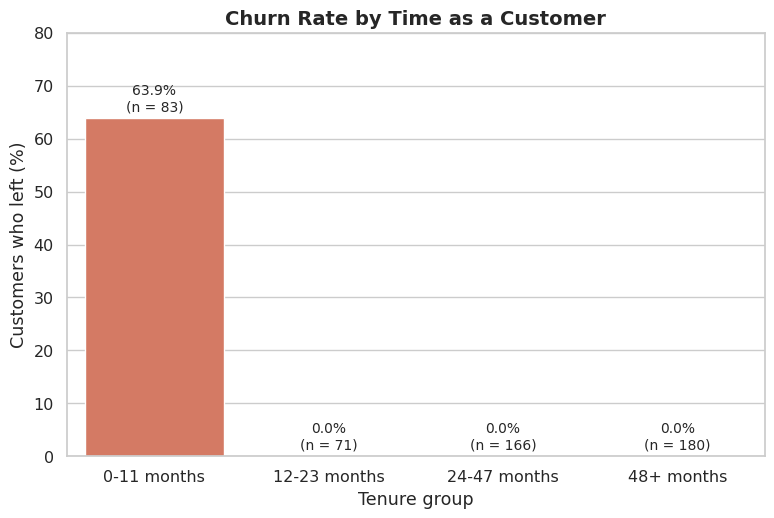

Chart 1: every customer who left had been with the company less than 12 months.



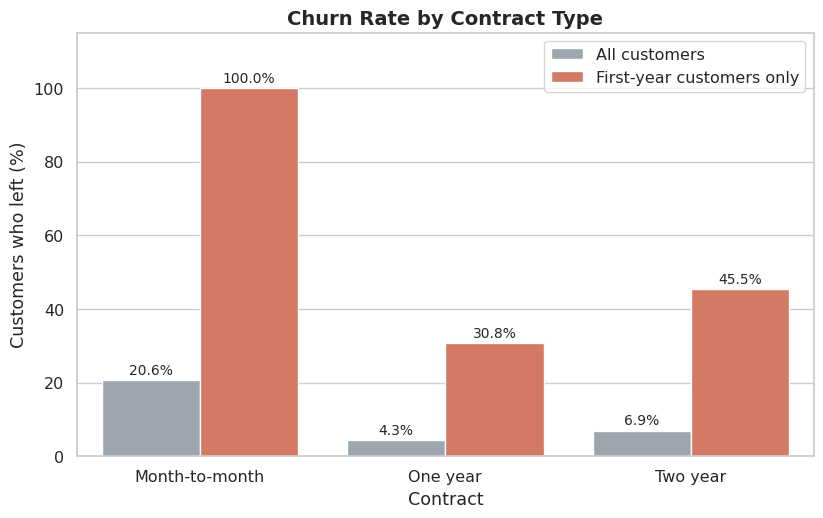

Chart 2: 35 of 35 first-year month-to-month customers left.



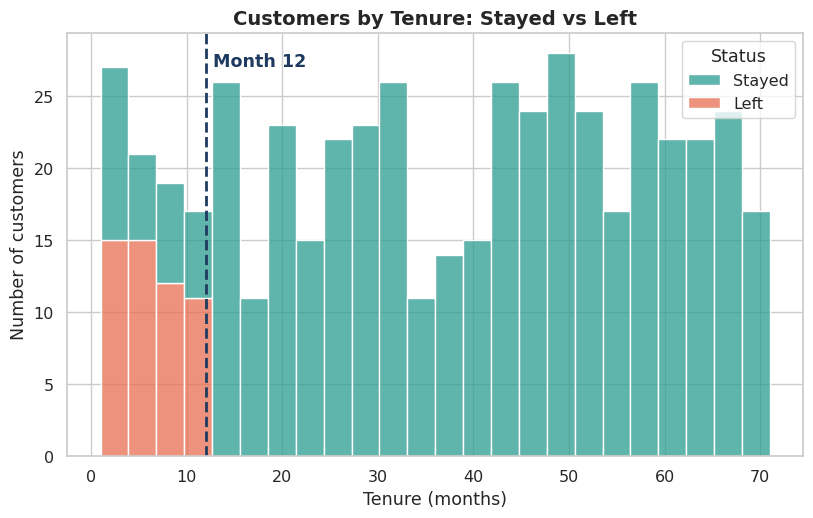

Chart 3: the longest tenure of a customer who left is 11 months.



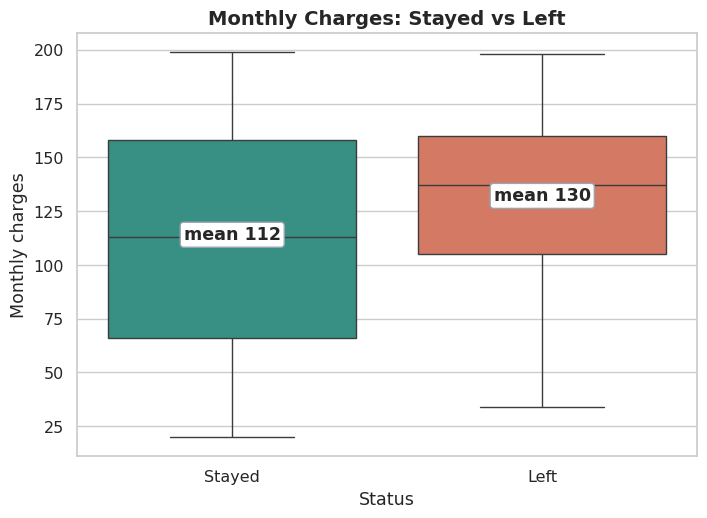

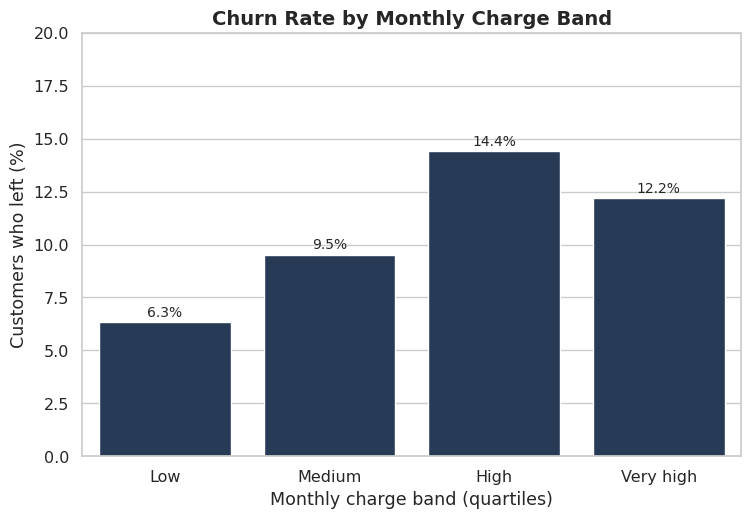

Chart 5: churn is highest in the 'High' charge band (14.4%) and lowest in the 'Low' band (6.3%).



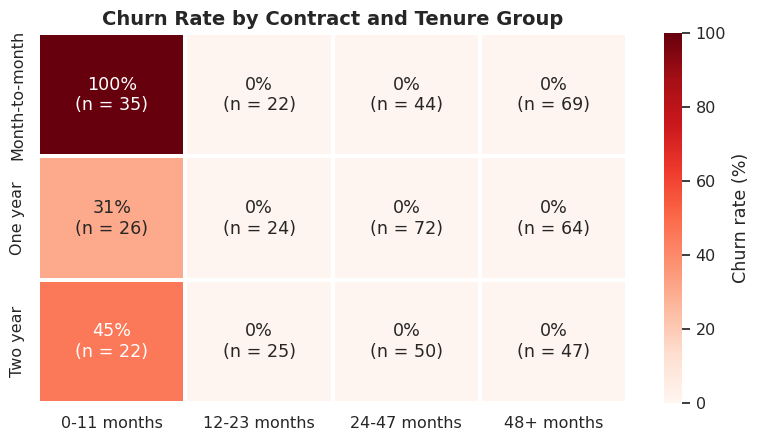

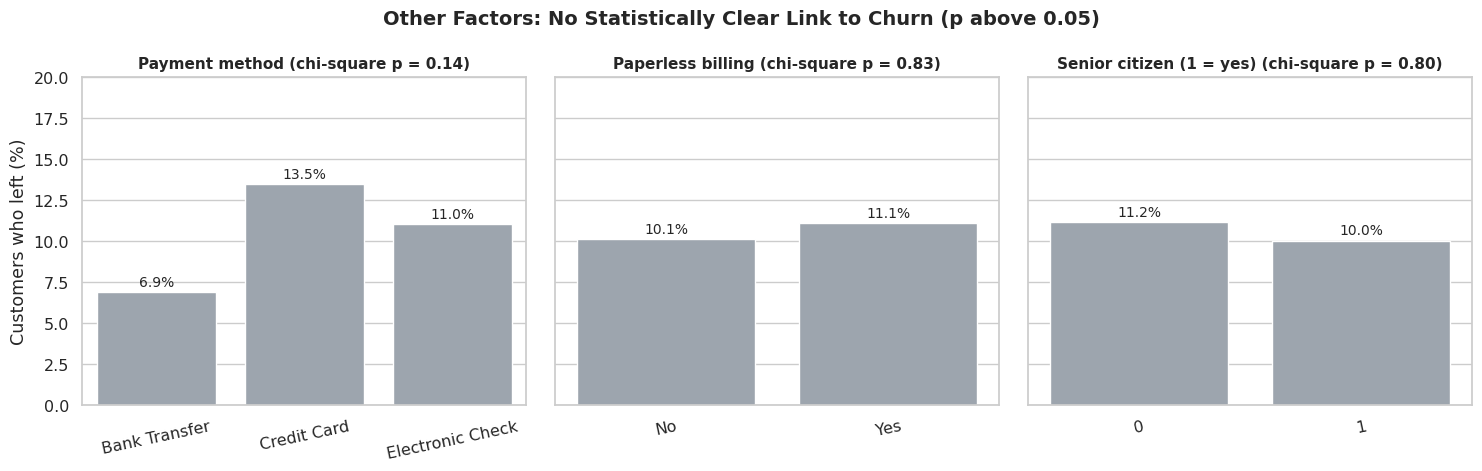

Chart 7: chi-square tests of each factor against churn -> Payment method: p = 0.14; Paperless billing: p = 0.83; Senior citizen (1 = yes): p = 0.80
A p-value above 0.05 means the differences you see could easily be chance.


In [2]:
# Step 2: Exploratory data analysis (EDA) with 7 professional charts

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', font_scale=1.05)
TEAL, ORANGE, NAVY, GREY = '#2a9d8f', '#e76f51', '#1f3a5f', '#9aa5b1'
df = clean.copy()
df['Status'] = df['Churn'].map({0: 'Stayed', 1: 'Left'})
STATUS_COLORS = {'Stayed': TEAL, 'Left': ORANGE}


def label_bars(ax, fmt="{:.1f}%", pad=0.5):
    for bar in ax.patches:
        if bar.get_height() > 0 or True:
            ax.annotate(fmt.format(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')


print("=" * 60)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)
print(f"Customers: {len(df)} | Left: {df['Churn'].sum()} ({df['Churn'].mean() * 100:.1f}%) | Stayed: {(1 - df['Churn']).sum()}")
print()
print("Average values for customers who stayed and customers who left:")
print(df.groupby('Status')[['Tenure', 'MonthlyCharges']].mean().round(1))
print()

# ---------- Chart 1: churn rate by how long the customer has stayed ----------
by_tenure = df.groupby('TenureGroup', observed=True)['Churn'].agg(['mean', 'count']).reset_index()
by_tenure['Rate'] = by_tenure['mean'] * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=by_tenure, x='TenureGroup', y='Rate', color=ORANGE, ax=ax)
for bar, n in zip(ax.patches, by_tenure['count']):
    ax.annotate(f"{bar.get_height():.1f}%\n(n = {n})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
ax.set_title('Churn Rate by Time as a Customer', fontsize=14, fontweight='bold')
ax.set_xlabel('Tenure group')
ax.set_ylabel('Customers who left (%)')
ax.set_ylim(0, 80)
plt.savefig('figures/1_churn_by_tenure.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 1: every customer who left had been with the company less than 12 months.\n")

# ---------- Chart 2: churn by contract, all customers vs first-year customers ----------
rows = []
for contract, g in df.groupby('Contract'):
    rows.append({'Contract': contract, 'Group': 'All customers', 'Rate': g['Churn'].mean() * 100})
    first = g[g['FirstYear'] == 1]
    rows.append({'Contract': contract, 'Group': 'First-year customers only', 'Rate': first['Churn'].mean() * 100})
cc = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(data=cc, x='Contract', y='Rate', hue='Group', palette=[GREY, ORANGE], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2, fontsize=10)
ax.set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
ax.set_ylabel('Customers who left (%)')
ax.set_ylim(0, 115)
ax.legend(title='', loc='upper right')
plt.savefig('figures/2_churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()
m2m_first = df[(df['Contract'] == 'Month-to-month') & (df['FirstYear'] == 1)]
print(f"Chart 2: {int(m2m_first['Churn'].sum())} of {len(m2m_first)} first-year month-to-month customers left.\n")

# ---------- Chart 3: tenure of customers who stayed and left ----------
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.histplot(data=df, x='Tenure', hue='Status', palette=STATUS_COLORS, bins=24, multiple='stack', ax=ax)
ax.axvline(12, color=NAVY, linestyle='--', linewidth=2)
ax.text(12.8, ax.get_ylim()[1] * 0.92, 'Month 12', color=NAVY, fontweight='bold')
ax.set_title('Customers by Tenure: Stayed vs Left', fontsize=14, fontweight='bold')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Number of customers')
plt.savefig('figures/3_tenure_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Chart 3: the longest tenure of a customer who left is {df.loc[df['Churn'] == 1, 'Tenure'].max()} months.\n")

# ---------- Chart 4: monthly charges of customers who stayed and left ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=df, x='Status', y='MonthlyCharges', hue='Status', order=['Stayed', 'Left'],
            palette=STATUS_COLORS, legend=False, ax=ax)
means = df.groupby('Status')['MonthlyCharges'].mean()
for i, status in enumerate(['Stayed', 'Left']):
    ax.annotate(f"mean {means[status]:.0f}", (i, means[status]), ha='center', fontweight='bold',
                xytext=(0, 0), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=GREY))
ax.set_title('Monthly Charges: Stayed vs Left', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly charges')
plt.savefig('figures/4_monthly_charges_by_status.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 5: churn rate by monthly-charge band ----------
by_band = df.groupby('ChargeBand', observed=True)['Churn'].mean().reset_index()
by_band['Rate'] = by_band['Churn'] * 100
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.barplot(data=by_band, x='ChargeBand', y='Rate', color=NAVY, ax=ax)
label_bars(ax)
ax.set_title('Churn Rate by Monthly Charge Band', fontsize=14, fontweight='bold')
ax.set_xlabel('Monthly charge band (quartiles)')
ax.set_ylabel('Customers who left (%)')
ax.set_ylim(0, 20)
plt.savefig('figures/5_churn_by_charge_band.png', dpi=150, bbox_inches='tight')
plt.show()
best = by_band.loc[by_band['Rate'].idxmax()]
worst = by_band.loc[by_band['Rate'].idxmin()]
print(f"Chart 5: churn is highest in the '{best['ChargeBand']}' charge band ({best['Rate']:.1f}%) and lowest in the '{worst['ChargeBand']}' band ({worst['Rate']:.1f}%).\n")

# ---------- Chart 6: heatmap of churn by contract and tenure group ----------
rate = df.pivot_table(index='Contract', columns='TenureGroup', values='Churn', aggfunc='mean', observed=True) * 100
count = df.pivot_table(index='Contract', columns='TenureGroup', values='Churn', aggfunc='count', observed=True)
labels = rate.round(0).astype(int).astype(str) + '%\n(n = ' + count.astype(int).astype(str) + ')'
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(rate, annot=labels, fmt='', cmap='Reds', vmin=0, vmax=100, linewidths=1.5, linecolor='white',
            cbar_kws={'label': 'Churn rate (%)'}, ax=ax)
ax.set_title('Churn Rate by Contract and Tenure Group', fontsize=14, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('')
plt.savefig('figures/6_churn_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 7: other factors, tested for a link with churn ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
summary = []
for ax, col, title in zip(axes, ['PaymentMethod', 'PaperlessBilling', 'SeniorCitizen'],
                          ['Payment method', 'Paperless billing', 'Senior citizen (1 = yes)']):
    r = df.groupby(col)['Churn'].mean().reset_index()
    r['Rate'] = r['Churn'] * 100
    p_value = stats.chi2_contingency(pd.crosstab(df[col], df['Churn']))[1]
    sns.barplot(data=r, x=col, y='Rate', color=GREY, ax=ax)
    label_bars(ax)
    ax.set_title(f"{title} (chi-square p = {p_value:.2f})", fontweight='bold', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Customers who left (%)')
    ax.set_ylim(0, 20)
    ax.tick_params(axis='x', rotation=12)
    summary.append(f"{title}: p = {p_value:.2f}")
fig.suptitle('Other Factors: No Statistically Clear Link to Churn (p above 0.05)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/7_other_factors.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 7: chi-square tests of each factor against churn -> " + "; ".join(summary))
print("A p-value above 0.05 means the differences you see could easily be chance.")

TECHNIQUE 1: HYPOTHESIS TESTS (alpha = 0.05)
A. Churn depends on contract type (chi-square)
   chi-square = 27.72; p = 9.59e-07 -> significant; adjusted p (x3) = 2.88e-06 (survives the correction)

B. First year: month-to-month leave more than other contracts (Fisher exact)
   month-to-month 35 of 35 left, other contracts 18 of 48 left; p = 2.22e-10 -> significant; adjusted p (x3) = 6.66e-10 (survives the correction)

C. Customers who left pay different monthly charges (Mann-Whitney)
   median 137 (left) vs 113 (stayed); p = 0.0183 -> significant; adjusted p (x3) = 0.0548 (does NOT survive the correction)

TECHNIQUE 2: CUSTOMER RISK SEGMENTS
                                  Segment  Customers  Left  Churn_rate  Avg_monthly_charge  Monthly_revenue  Monthly_revenue_lost  Share_of_customers_%  Share_of_revenue_lost_%
  1 Critical: first year + month-to-month         35    35       100.0               120.9             4233                4233.0                   7.0                     6

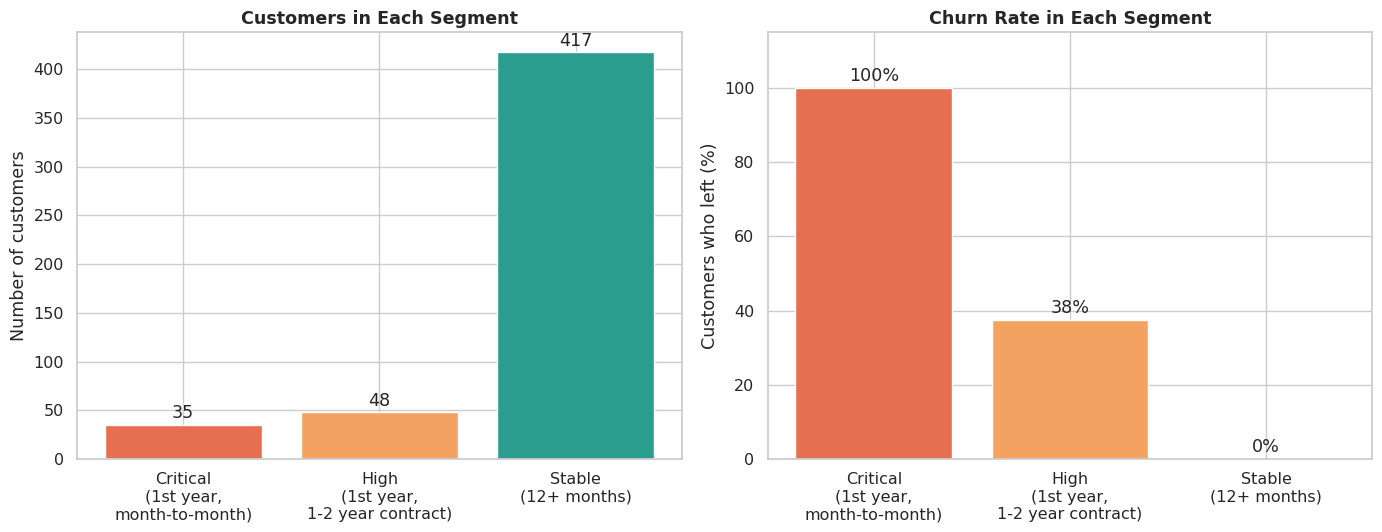

TECHNIQUE 3: PREDICTING WHO WILL LEAVE
Two sets of information are compared:
  Model A uses everything, including Tenure.
  Model B uses only what a company knows when a customer signs up (no Tenure).

                   Model                  Method  ROC-AUC  Caught (recall)  Correct alerts (precision)  Accuracy
   Model A (with Tenure)     Logistic regression    0.980            0.981                       0.536     0.908
   Model A (with Tenure) Decision tree (depth 3)    0.971            0.981                       0.658     0.944
Model B (without Tenure)     Logistic regression    0.691            0.642                       0.193     0.678
Model B (without Tenure) Decision tree (depth 3)    0.668            0.755                       0.160     0.554

Baseline: always guessing 'stays' is correct 89.4% of the time but catches 0 customers who leave.

HOW TO READ THIS (ROC-AUC: 0.5 = guessing, 1.0 = perfect):
  Model A reaches 0.98, but be careful: for customers who left, Tenure is 

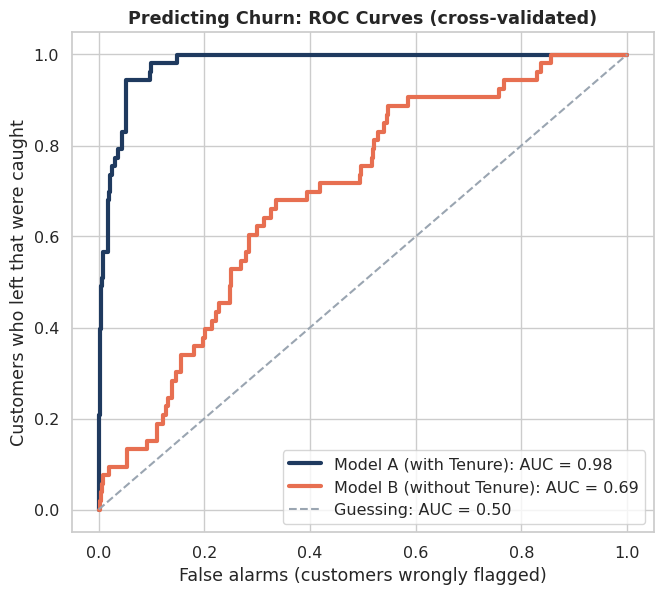

In [3]:
# Step 3: Advanced analysis with 3 techniques
#   Technique 1: statistical hypothesis tests
#   Technique 2: customer risk segmentation
#   Technique 3: prediction models checked with cross-validation

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

analysis_results = []          # saved for the report

# =====================================================================
# TECHNIQUE 1: HYPOTHESIS TESTS (3 tests, with a strict multiple-test check)
# =====================================================================
print("=" * 60)
print("TECHNIQUE 1: HYPOTHESIS TESTS (alpha = 0.05)")
print("=" * 60)
tests = []

# Test A: is churn linked with the contract type?
table_a = pd.crosstab(df['Contract'], df['Churn'])
chi2, p_a, dof, _ = stats.chi2_contingency(table_a)
tests.append(("A. Churn depends on contract type (chi-square)", f"chi-square = {chi2:.2f}", p_a))

# Test B: among first-year customers, do month-to-month customers leave more than the others?
first = df[df['FirstYear'] == 1]
m2m = first['Contract'] == 'Month-to-month'
table_b = [[int(first.loc[m2m, 'Churn'].sum()), int((1 - first.loc[m2m, 'Churn']).sum())],
           [int(first.loc[~m2m, 'Churn'].sum()), int((1 - first.loc[~m2m, 'Churn']).sum())]]
odds, p_b = stats.fisher_exact(table_b)
tests.append(("B. First year: month-to-month leave more than other contracts (Fisher exact)",
              f"month-to-month {table_b[0][0]} of {sum(table_b[0])} left, other contracts {table_b[1][0]} of {sum(table_b[1])} left", p_b))

# Test C: do customers who left pay different monthly charges?
left_mc = df.loc[df['Churn'] == 1, 'MonthlyCharges']
stay_mc = df.loc[df['Churn'] == 0, 'MonthlyCharges']
u, p_c = stats.mannwhitneyu(left_mc, stay_mc)
tests.append(("C. Customers who left pay different monthly charges (Mann-Whitney)",
              f"median {left_mc.median():.0f} (left) vs {stay_mc.median():.0f} (stayed)", p_c))

for name, detail, p in tests:
    adjusted = min(p * len(tests), 1)
    decision = "significant" if p < 0.05 else "not significant"
    survives = "survives" if adjusted < 0.05 else "does NOT survive"
    line = f"{name}\n   {detail}; p = {p:.3g} -> {decision}; adjusted p (x{len(tests)}) = {adjusted:.3g} ({survives} the correction)"
    print(line)
    print()
    analysis_results.append(line)

# =====================================================================
# TECHNIQUE 2: CUSTOMER RISK SEGMENTATION
# =====================================================================
print("=" * 60)
print("TECHNIQUE 2: CUSTOMER RISK SEGMENTS")
print("=" * 60)


def segment(row):
    if row['FirstYear'] == 1 and row['Contract'] == 'Month-to-month':
        return '1 Critical: first year + month-to-month'
    if row['FirstYear'] == 1:
        return '2 High: first year + 1 or 2 year contract'
    return '3 Stable: 12 months or more'


df['Segment'] = df.apply(segment, axis=1)
seg = df.groupby('Segment').agg(Customers=('Churn', 'count'), Left=('Churn', 'sum'),
                                Churn_rate=('Churn', 'mean'), Avg_monthly_charge=('MonthlyCharges', 'mean'),
                                Monthly_revenue=('MonthlyCharges', 'sum')).reset_index()
lost = df[df['Churn'] == 1].groupby('Segment')['MonthlyCharges'].sum().rename('Monthly_revenue_lost')
seg = seg.merge(lost, on='Segment', how='left').fillna(0)
seg['Churn_rate'] = seg['Churn_rate'] * 100
seg['Share_of_customers_%'] = seg['Customers'] / seg['Customers'].sum() * 100
seg['Share_of_revenue_lost_%'] = seg['Monthly_revenue_lost'] / seg['Monthly_revenue_lost'].sum() * 100
print(seg.round(1).to_string(index=False))
analysis_results.append("RISK SEGMENTS\n" + seg.round(1).to_string(index=False))
total_lost = seg['Monthly_revenue_lost'].sum()
total_rev = seg['Monthly_revenue'].sum()
print()
print(f"Monthly revenue of all customers: {total_rev:,.0f}")
print(f"Monthly revenue lost to churn: {total_lost:,.0f} ({total_lost / total_rev * 100:.1f}% of the total)")
print("All of the lost revenue comes from customers in their first year.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
short = ['Critical\n(1st year,\nmonth-to-month)', 'High\n(1st year,\n1-2 year contract)', 'Stable\n(12+ months)']
axes[0].bar(short, seg['Customers'], color=[ORANGE, '#f4a261', TEAL])
axes[0].set_title('Customers in Each Segment', fontweight='bold')
axes[0].set_ylabel('Number of customers')
for i, v in enumerate(seg['Customers']):
    axes[0].annotate(f"{int(v)}", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
axes[1].bar(short, seg['Churn_rate'], color=[ORANGE, '#f4a261', TEAL])
axes[1].set_title('Churn Rate in Each Segment', fontweight='bold')
axes[1].set_ylabel('Customers who left (%)')
axes[1].set_ylim(0, 115)
for i, v in enumerate(seg['Churn_rate']):
    axes[1].annotate(f"{v:.0f}%", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.savefig('figures/8_risk_segments.png', dpi=150, bbox_inches='tight')
plt.show()

# =====================================================================
# TECHNIQUE 3: PREDICTION MODELS (5-fold cross-validation)
# =====================================================================
print("=" * 60)
print("TECHNIQUE 3: PREDICTING WHO WILL LEAVE")
print("=" * 60)
print("Two sets of information are compared:")
print("  Model A uses everything, including Tenure.")
print("  Model B uses only what a company knows when a customer signs up (no Tenure).\n")
FEATURES_A = ['Tenure', 'MonthlyCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']
FEATURES_B = ['MonthlyCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = df['Churn']


def build(features, model):
    categorical = list(df[features].select_dtypes(exclude='number').columns)
    numeric = [c for c in features if c not in categorical]
    pre = ColumnTransformer([('num', StandardScaler(), numeric),
                             ('cat', OneHotEncoder(drop='first'), categorical)])
    return make_pipeline(pre, model)


results = []
probabilities = {}
for label, features in [('Model A (with Tenure)', FEATURES_A), ('Model B (without Tenure)', FEATURES_B)]:
    for model_name, model in [('Logistic regression', LogisticRegression(max_iter=1000, class_weight='balanced')),
                              ('Decision tree (depth 3)', DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42))]:
        pipe = build(features, model)
        prob = cross_val_predict(pipe, df[features], y, cv=cv, method='predict_proba')[:, 1]
        probabilities[(label, model_name)] = prob
        predicted = (prob >= 0.5).astype(int)
        results.append({'Model': label, 'Method': model_name,
                        'ROC-AUC': roc_auc_score(y, prob),
                        'Caught (recall)': ((predicted == 1) & (y == 1)).sum() / (y == 1).sum(),
                        'Correct alerts (precision)': ((predicted == 1) & (y == 1)).sum() / max((predicted == 1).sum(), 1),
                        'Accuracy': (predicted == y).mean()})
res = pd.DataFrame(results)
print(res.round(3).to_string(index=False))
print()
print(f"Baseline: always guessing 'stays' is correct {(1 - y.mean()) * 100:.1f}% of the time but catches 0 customers who leave.")
analysis_results.append("PREDICTION MODELS (5-fold cross-validation)\n" + res.round(3).to_string(index=False))

auc_a = res.loc[(res['Model'].str.startswith('Model A')) & (res['Method'] == 'Logistic regression'), 'ROC-AUC'].iloc[0]
auc_b = res.loc[(res['Model'].str.startswith('Model B')) & (res['Method'] == 'Logistic regression'), 'ROC-AUC'].iloc[0]
print()
print("HOW TO READ THIS (ROC-AUC: 0.5 = guessing, 1.0 = perfect):")
print(f"  Model A reaches {auc_a:.2f}, but be careful: for customers who left, Tenure is the time they stayed before leaving.")
print("  A customer with 40 months of tenure cannot be a first-year leaver, so Tenure partly 'knows' the answer.")
print("  The file does not say how Tenure was recorded for customers who left, so Model A is likely too optimistic.")
print(f"  Model B (information known at sign-up) reaches only {auc_b:.2f}: contract, payment method and charges")
print("  alone are a weak signal. A company should not expect a sharp individual prediction from this data.")
print("  What the data does support is the SEGMENT view above: new customers on month-to-month contracts are the risk.")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for (label, model_name), prob in probabilities.items():
    if model_name != 'Logistic regression':
        continue
    fpr, tpr, _ = roc_curve(y, prob)
    ax.plot(fpr, tpr, linewidth=3, label=f"{label}: AUC = {roc_auc_score(y, prob):.2f}",
            color=NAVY if 'A' in label.split()[1] else ORANGE)
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', label='Guessing: AUC = 0.50')
ax.set_title('Predicting Churn: ROC Curves (cross-validated)', fontweight='bold')
ax.set_xlabel('False alarms (customers wrongly flagged)')
ax.set_ylabel('Customers who left that were caught')
ax.legend(loc='lower right')
plt.savefig('figures/9_model_roc.png', dpi=150, bbox_inches='tight')
plt.show()

REVENUE AT RISK (from the data)
Customers who left: 53 of 500 (10.6%)
Monthly revenue lost: 6,878 (12.1% of all monthly revenue)
Over 12 months that is 82,536
Average monthly charge of a customer who left: 129.8 (customers who stayed: 111.7)

RETENTION PROGRAMME SCENARIOS (based on assumptions)
Programme idea: contact new customers early, offer help and a welcome benefit, and
offer a discount to switch from a month-to-month to a longer contract.
Assumptions: programme cost = 0.5 to 1.0 x one month's charge per enrolled customer; a saved customer is worth 12 months of charges.

                Strategy Churn reduction Cost level  Enrolled  Customers saved  Revenue saved  Programme cost  Net benefit  ROI %
   Critical segment only             10%   Low cost        35              4.0         5080.0          2116.0       2963.0  140.0
   Critical segment only             10%  High cost        35              4.0         5080.0          4233.0        847.0   20.0
   Critical segment only  

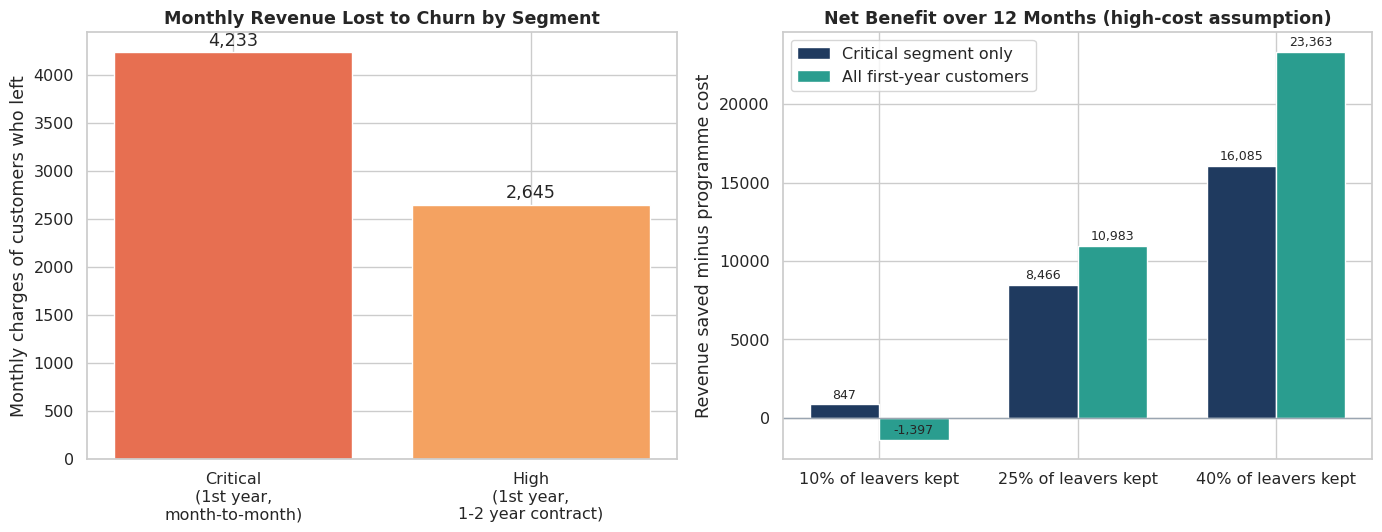

IMPLEMENTATION PLAN
Days 1-30 | Prepare
   Actions: Flag every new customer and its contract type at sign-up; fix the TotalCharges billing data; agree the offer budget
   Metric:  Share of new customers flagged  ->  Target: 100%

Days 31-60 | Pilot
   Actions: Start the programme for new customers: welcome call in week 1, check-in in month 3, month-to-month customers offered a longer contract. Keep a control group with no programme
   Metric:  Customers enrolled  ->  Target: Half of all new customers enrolled

Days 61-120 | Measure
   Actions: Compare churn of enrolled customers with the control group; check cost per customer
   Metric:  First-year churn: programme vs control  ->  Target: Lower than control

Days 121-180 | Decide and scale
   Actions: If the pilot keeps enough customers to pay for itself (see the break-even above), roll out to all new customers; if not, change the offer and test again
   Metric:  Net benefit per 100 new customers  ->  Target: Above 0

Ongoing | Monitor

In [4]:
# Step 4: Revenue at risk, retention scenarios and the implementation plan
# IMPORTANT: the scenario numbers use ASSUMPTIONS (marked below). They are not facts from the data.
# The data has no information about the cost or the effect of a retention programme.

# ---------- Assumptions you can change ----------
CHURN_REDUCTIONS = [0.10, 0.25, 0.40]          # share of would-be leavers the programme manages to keep
COST_LEVELS = {'Low cost': 0.5, 'High cost': 1.0}   # programme cost per enrolled customer, as a multiple of one month's charge
VALUE_MONTHS = 12                              # a saved customer is worth 12 months of charges (cautious)

first_year = df[df['FirstYear'] == 1]
critical = df[df['Segment'].str.startswith('1')]
leavers = df[df['Churn'] == 1]

print("=" * 60)
print("REVENUE AT RISK (from the data)")
print("=" * 60)
monthly_lost = leavers['MonthlyCharges'].sum()
print(f"Customers who left: {len(leavers)} of {len(df)} ({len(leavers) / len(df) * 100:.1f}%)")
print(f"Monthly revenue lost: {monthly_lost:,.0f} ({monthly_lost / df['MonthlyCharges'].sum() * 100:.1f}% of all monthly revenue)")
print(f"Over {VALUE_MONTHS} months that is {monthly_lost * VALUE_MONTHS:,.0f}")
print(f"Average monthly charge of a customer who left: {leavers['MonthlyCharges'].mean():.1f} "
      f"(customers who stayed: {df.loc[df['Churn'] == 0, 'MonthlyCharges'].mean():.1f})")
print()

# ---------- Scenarios ----------
print("=" * 60)
print("RETENTION PROGRAMME SCENARIOS (based on assumptions)")
print("=" * 60)
print("Programme idea: contact new customers early, offer help and a welcome benefit, and")
print("offer a discount to switch from a month-to-month to a longer contract.")
print(f"Assumptions: programme cost = {COST_LEVELS['Low cost']} to {COST_LEVELS['High cost']} x one month's charge per enrolled customer; "
      f"a saved customer is worth {VALUE_MONTHS} months of charges.\n")

strategies = {'Critical segment only': critical, 'All first-year customers': first_year}
rows = []
for strategy, group in strategies.items():
    group_leavers = group[group['Churn'] == 1]
    for reduction in CHURN_REDUCTIONS:
        for level, factor in COST_LEVELS.items():
            saved = len(group_leavers) * reduction
            revenue_saved = saved * group_leavers['MonthlyCharges'].mean() * VALUE_MONTHS
            cost = len(group) * factor * group['MonthlyCharges'].mean()
            rows.append({'Strategy': strategy, 'Churn reduction': f"{reduction * 100:.0f}%", 'Cost level': level,
                         'Enrolled': len(group), 'Customers saved': round(saved, 1),
                         'Revenue saved': revenue_saved, 'Programme cost': cost,
                         'Net benefit': revenue_saved - cost, 'ROI %': (revenue_saved - cost) / cost * 100})
scen = pd.DataFrame(rows)
print(scen.round(0).to_string(index=False))
analysis_results.append("RETENTION SCENARIOS (assumption-based)\n" + scen.round(0).to_string(index=False))

print()
print("BREAK-EVEN: the share of would-be leavers the programme must keep to pay for itself")
break_even_values = []
for strategy, group in strategies.items():
    group_leavers = group[group['Churn'] == 1]
    for level, factor in COST_LEVELS.items():
        cost = len(group) * factor * group['MonthlyCharges'].mean()
        value_each = group_leavers['MonthlyCharges'].mean() * VALUE_MONTHS
        needed = cost / (len(group_leavers) * value_each) * 100
        break_even_values.append(needed)
        print(f"  {strategy} ({level}): {needed:.0f}%")
        analysis_results.append(f"Break-even, {strategy} ({level}): {needed:.0f}% of would-be leavers must be kept")
print()
losing = int((scen['Net benefit'] < 0).sum())
print(f"Reading the table: under these assumptions the programme pays for itself if it keeps {min(break_even_values):.0f}% to {max(break_even_values):.0f}% of the customers who would leave.")
print(f"{len(scen) - losing} of the {len(scen)} scenarios have a positive net benefit; {losing} lose money (a costly offer that keeps few customers).")
print("These are scenarios, not forecasts. The real effect must be measured with a test (see the plan below).")

# ---------- Chart ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
seg_lost = leavers.groupby('Segment')['MonthlyCharges'].sum()
axes[0].bar(['Critical\n(1st year,\nmonth-to-month)', 'High\n(1st year,\n1-2 year contract)'],
            [seg_lost.iloc[0], seg_lost.iloc[1]], color=[ORANGE, '#f4a261'])
axes[0].set_title('Monthly Revenue Lost to Churn by Segment', fontweight='bold')
axes[0].set_ylabel('Monthly charges of customers who left')
for i, v in enumerate([seg_lost.iloc[0], seg_lost.iloc[1]]):
    axes[0].annotate(f"{v:,.0f}", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')

plot = scen[scen['Cost level'] == 'High cost']
width = 0.35
x_positions = np.arange(len(CHURN_REDUCTIONS))
for i, (strategy, color) in enumerate(zip(strategies, [NAVY, TEAL])):
    sub = plot[plot['Strategy'] == strategy]
    bars = axes[1].bar(x_positions + (i - 0.5) * width, sub['Net benefit'], width, label=strategy, color=color)
    for bar in bars:
        axes[1].annotate(f"{bar.get_height():,.0f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
axes[1].axhline(0, color=GREY, linewidth=1)
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels([f"{r * 100:.0f}% of leavers kept" for r in CHURN_REDUCTIONS])
axes[1].set_title('Net Benefit over 12 Months (high-cost assumption)', fontweight='bold')
axes[1].set_ylabel('Revenue saved minus programme cost')
axes[1].legend()
plt.tight_layout()
plt.savefig('figures/10_business_impact.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Implementation plan ----------
print("=" * 60)
print("IMPLEMENTATION PLAN")
print("=" * 60)
plan = pd.DataFrame([
    ['Days 1-30', 'Prepare', 'Flag every new customer and its contract type at sign-up; fix the TotalCharges billing data; agree the offer budget', 'Share of new customers flagged', '100%'],
    ['Days 31-60', 'Pilot', 'Start the programme for new customers: welcome call in week 1, check-in in month 3, month-to-month customers offered a longer contract. Keep a control group with no programme', 'Customers enrolled', 'Half of all new customers enrolled'],
    ['Days 61-120', 'Measure', 'Compare churn of enrolled customers with the control group; check cost per customer', 'First-year churn: programme vs control', 'Lower than control'],
    ['Days 121-180', 'Decide and scale', 'If the pilot keeps enough customers to pay for itself (see the break-even above), roll out to all new customers; if not, change the offer and test again', 'Net benefit per 100 new customers', 'Above 0'],
    ['Ongoing', 'Monitor', 'Track first-year churn and month-to-month share every month; record how Tenure is measured for customers who leave', 'First-year churn rate', 'Below the current level']],
    columns=['When', 'Phase', 'Actions', 'Metric', 'Target'])
pd.set_option('display.max_colwidth', 200)
for _, row in plan.iterrows():
    print(f"{row['When']} | {row['Phase']}\n   Actions: {row['Actions']}\n   Metric:  {row['Metric']}  ->  Target: {row['Target']}\n")
analysis_results.append("IMPLEMENTATION PLAN\n" + plan.to_string(index=False))